# Verify patient-grouped folds: deduplicated Subset data

We want to evaluate models on people whose images they have not seen during training. This notebook verifies the original five repeatable groups after exact-copy retention, keeping each patient's images together. The historical splitter aimed for similar malignant-image percentages; the clean branch preserves those groups rather than rebalancing them.

It follows [02_clean_data_eda.ipynb](02_clean_data_eda.ipynb). The saved `train_folds.csv` lets later models use the same held-out patients, making their comparisons more useful. The reserved test stays separate.


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [03_patient_splitting.ipynb](../Subset/03_patient_splitting.ipynb).

Original fold-table and single-panel plot templates are preserved. Creating assignments and reading reserved-test IDs are explicitly replaced by verification of frozen development memberships and a deferred-test status.

## Why group by patient?

Images from one person may share patient-specific details. If they appear in both training and evaluation, a model could benefit from that overlap. Each patient therefore belongs to one **fold**, one of five groups. Five-fold cross-validation trains on four groups and predicts the fifth, repeating until every image has a held-out prediction.

`StratifiedGroupKFold` was the original splitting tool: it keeps patients together and tries to balance image labels. Exact balance may be impossible when whole patients move together. Seed 42 makes the assignment repeatable; we do not search seeds for a favourable score.


**Deduplication adaptation:** removing 158 exact copies changes image counts within groups but does not change any patient's assignment. Rerunning the splitter after removal could move patients, mixing the effect of data cleaning with the effect of a new partition. This report therefore reads and checks existing memberships only.

## Set the paths and fold settings

Use the frozen deduplicated training file and the original five folds. Seed 42 records the historical assignment; it is not used to generate a new split. The code finds the project folder and names the existing saved table and separate clean figure. Later models should use this saved assignment rather than make a new split for each comparison.

In [1]:
NOTEBOOK_STAGE = '03_patient_fold_verification'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary

from matplotlib.ticker import PercentFormatter
PROJECT_ROOT = ROOT
PROCESSED_DIR = ROOT / "data/subset/processed/dedup_v1"
TRAIN_FOLDS_PATH = PROCESSED_DIR / "train_folds.csv"
IMAGE_RATE_FIGURE_PATH = FIGURE_DIR / "patient_split_image_malignancy_rate_dedup_v1.png"
N_SPLITS = 5
RANDOM_STATE = 42  # Original partition provenance, not a new split.
print(f"Project root: {PROJECT_ROOT}")
print(f"Frozen fold input: {TRAIN_FOLDS_PATH}")
ORIGINAL_EXPORT_DPI = 320


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

Project root: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma
Frozen fold input: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\dedup_v1\train_folds.csv


### Load the cleaned training records

The counts below describe the records available for cross-validation. A positive patient has at least one malignant image, even if that patient also has benign images. Patient identifiers control the split; they are not a model feature.

In [2]:
train = data.drop(columns="fold").copy()
train["age_approx"] = train["age_approx"].astype("string")

patient_targets = train.groupby("patient_id")["target"].max()
input_summary = pd.Series(
    {
        "images": len(train),
        "patients": train["patient_id"].nunique(),
        "malignant images": int(train["target"].sum()),
        "positive patients": int(patient_targets.sum()),
    },
    name="count",
)
print(input_summary.to_string())


images               6706
patients              422
malignant images      127
positive patients      88


## Verify the five preserved folds

The next cell reads the existing `fold` value for every retained training row, labelled 0 through 4. Those numbers identify groups; they do not indicate risk or a ranking. All retained image rows and labels remain in place.

**Scope adaptation:** the original cell assigned folds. This cell instead checks that image-to-patient and image-to-fold mappings match the historical source and that all original patients remain. No splitting function is called, and fold balance is not used to revise memberships.

In [3]:
train_folds = data.copy()
train_folds["age_approx"] = train_folds["age_approx"].astype("string")
original_folds = pd.read_csv(ROOT / context["manifest"]["original_source"]["path"])
before = original_folds.set_index("image_name")
assert set(original_folds.patient_id) == set(train_folds.patient_id)
assert np.array_equal(before.loc[train_folds.image_name, "patient_id"].to_numpy(),
                      train_folds.patient_id.to_numpy())
assert np.array_equal(before.loc[train_folds.image_name, "fold"].to_numpy(),
                      train_folds.fold.to_numpy())
print(f"Preserved folds: {sorted(train_folds['fold'].unique().tolist())}")
print(f"Fold dtype: {train_folds['fold'].dtype}")
print("Changed patient memberships: 0; splitter called: False")

Preserved folds: [0, 1, 2, 3, 4]
Fold dtype: int64
Changed patient memberships: 0; splitter called: False


### Read the fold table

Each row describes one fold. Compare the number of images, the number of malignant images and their percentage. Then check the number of patients and the percentage with at least one malignant image.

Similar image percentages support comparable evaluation groups. Patient percentages can vary because the original assignment balanced image-level targets while keeping whole patients together. This table checks the split, rather than measuring prediction quality.

Clean held-out support ranges from 24 to 26 malignant images after one malignant copy is removed. The before-and-after table added below makes this change explicit; it is not evidence of predictive performance.

In [4]:
image_summary = train_folds.groupby("fold")["target"].agg(
    images="size",
    malignant_images="sum",
    image_malignancy_rate="mean",
)

patient_fold_targets = train_folds.groupby(["fold", "patient_id"])["target"].max()
patient_summary = patient_fold_targets.groupby("fold").agg(
    patients="size",
    positive_patients="sum",
    patient_positivity_rate="mean",
)

fold_summary = image_summary.join(patient_summary)
display_summary = fold_summary.copy()
display_summary["image_malignancy_rate"] = display_summary["image_malignancy_rate"].map(
    lambda value: f"{value:.2%}"
)
display_summary["patient_positivity_rate"] = display_summary["patient_positivity_rate"].map(
    lambda value: f"{value:.2%}"
)
display_summary


,images,malignant_images,image_malignancy_rate,patients,positive_patients,patient_positivity_rate
fold,,,,,,
0,1344,24,1.79%,84,17,20.24%
1,1366,26,1.90%,84,15,17.86%
2,1328,26,1.96%,87,21,24.14%
3,1371,25,1.82%,82,18,21.95%
4,1297,26,2.00%,85,17,20.00%


### Read the fold-balance figure

The horizontal axis lists folds 0 to 4. Each blue bar's height is malignant images divided by all images in that fold, shown as a percentage on the vertical axis. The dashed grey line is the percentage across all retained training images.

Bars near the line show that the preserved split has a similar malignant-image share. Higher bars are not better: here we want comparable class balance. The chart cannot show whether patients overlap, so the explicit checks below are still needed.

The figure retains the original one-panel composition, blue fill, dark blue outlines, percentage labels and dashed grey baseline. A separate supplementary patient-support figure follows instead of changing the original panel's meaning.

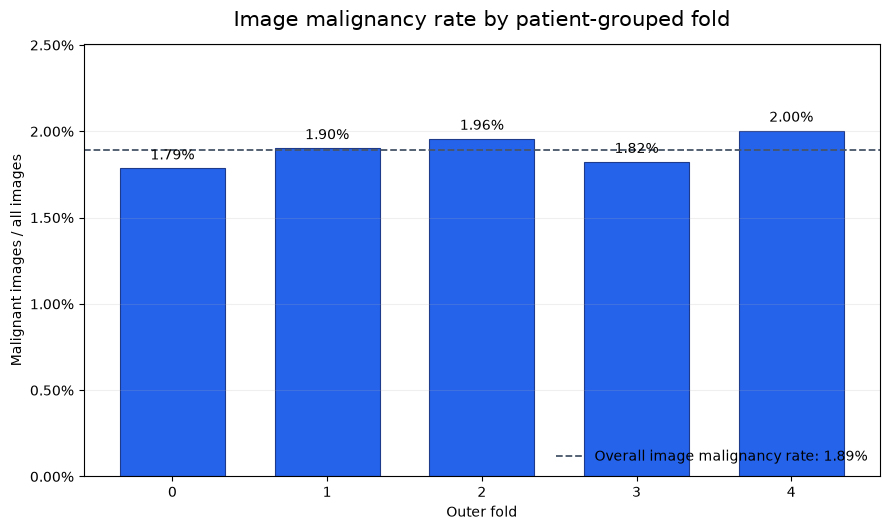

In [5]:
fold_image_rates = fold_summary["image_malignancy_rate"]
overall_image_rate = train_folds["target"].mean()

figure, axis = plt.subplots(figsize=(9, 5.4))
bars = axis.bar(
    fold_image_rates.index.astype(str),
    fold_image_rates.values,
    color="#2563EB",
    edgecolor="#1E3A8A",
    linewidth=0.8,
    width=0.68,
)
axis.bar_label(
    bars,
    labels=[f"{rate:.2%}" for rate in fold_image_rates],
    padding=4,
    fontsize=10,
)
axis.axhline(
    overall_image_rate,
    color="#475569",
    linestyle="--",
    linewidth=1.3,
    label=f"Overall image malignancy rate: {overall_image_rate:.2%}",
)

axis.set_title("Image malignancy rate by patient-grouped fold", fontsize=15, pad=13)
axis.set_xlabel("Outer fold")
axis.set_ylabel("Malignant images / all images")
axis.yaxis.set_major_formatter(PercentFormatter(1.0))
axis.set_ylim(0, fold_image_rates.max() * 1.25)
axis.grid(axis="y", alpha=0.20)
axis.legend(frameon=False, loc="lower right")
figure.tight_layout()

IMAGE_RATE_FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(IMAGE_RATE_FIGURE_PATH, dpi=320, bbox_inches="tight")
figure.savefig(IMAGE_RATE_FIGURE_PATH.with_suffix(".pdf"), bbox_inches="tight")
plt.show()
plt.close(figure)


## Compare before-and-after image and patient support

**Added retention accounting.** The table aligns original and retained counts for each unchanged outer fold. All patients remain while image counts fall according to the copy ledger. Similar image prevalence does not require identical patient-level prevalence; a patient is positive here if any of their images is malignant.

The supplementary patient chart uses the same blue bars, dark outlines, percentage labels and grey dashed overall reference as the original image chart. It is a separate figure because its denominator is patients, not images. Neither table nor plot chooses or revises the folds.

,fold,images_before,malignant_images_before,patients_before,images_after,malignant_images_after,patients_after,excluded_images,excluded_malignant
0,0,1370,25,84,1344,24,84,26,1
1,1,1372,26,84,1366,26,84,6,0
2,2,1381,26,87,1328,26,87,53,0
3,3,1371,25,82,1371,25,82,0,0
4,4,1370,26,85,1297,26,85,73,0


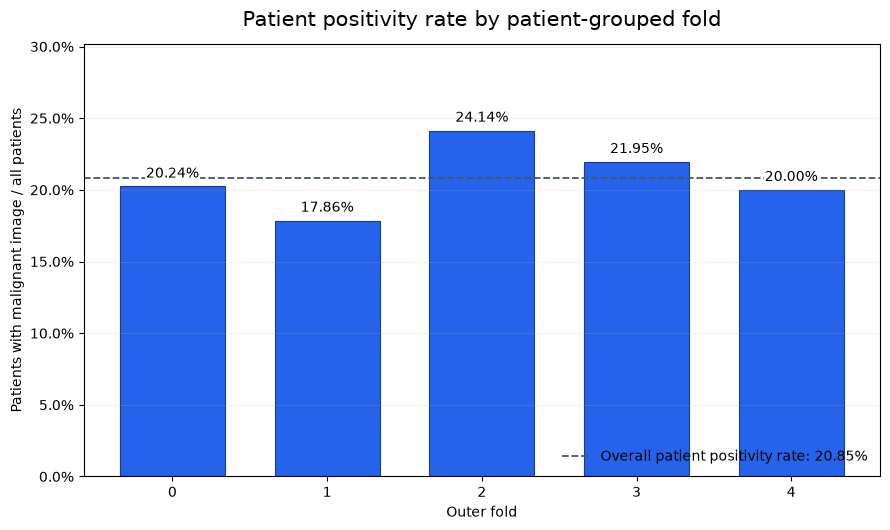

In [6]:
display(context["fold_counts"])
patient_rates = fold_summary.patient_positivity_rate
overall_patient_rate = train_folds.groupby("patient_id").target.max().mean()
figure, axis = plt.subplots(figsize=(9, 5.4))
bars = axis.bar(patient_rates.index.astype(str), patient_rates.values,
    color="#2563EB", edgecolor="#1E3A8A", linewidth=0.8, width=0.68)
percentage_labels = axis.bar_label(bars,
    labels=[f"{rate:.2%}" for rate in patient_rates], padding=4, fontsize=10)
axis.axhline(overall_patient_rate, color="#475569", linestyle="--", linewidth=1.3,
    label=f"Overall patient positivity rate: {overall_patient_rate:.2%}")
axis.set_title("Patient positivity rate by patient-grouped fold", fontsize=15, pad=13)
axis.set_xlabel("Outer fold")
axis.set_ylabel("Patients with malignant image / all patients")
axis.yaxis.set_major_formatter(PercentFormatter(1.0))
axis.set_ylim(0, patient_rates.max() * 1.25)
axis.grid(axis="y", alpha=0.20)
axis.legend(frameon=False, loc="lower right")
figure.tight_layout()
# Give only labels crossed by the reference line a white backing.
figure.canvas.draw()
reference_y = axis.transData.transform((0, overall_patient_rate))[1]
renderer = figure.canvas.get_renderer()
for annotation in percentage_labels:
    bounds = annotation.get_window_extent(renderer)
    if bounds.y0 <= reference_y <= bounds.y1:
        annotation.set_bbox({"facecolor": "white", "edgecolor": "none",
                             "boxstyle": "square,pad=0.08"})
finish_figure(figure, "patient_fold_balance")

### Check that every patient stays in one fold

Both printed counts should be zero: no row should lack a fold, and no patient should appear in multiple folds. We also check that the image order and row count remain unchanged relative to the retained input and that every fold contains both target classes. These checks prevent a balanced-looking chart from hiding an invalid assignment.

For each held-out outer fold, the additional check below compares fitting and held-out patient sets explicitly. Filtering identical copies cannot make a patient cross a fold boundary because each retained row preserves its original membership.

In [7]:
patient_fold_counts = train_folds.groupby("patient_id")["fold"].nunique()
patients_in_multiple_folds = int(patient_fold_counts.gt(1).sum())
unassigned_rows = int(train_folds["fold"].isna().sum())

assert len(train_folds) == len(train), "Row count changed during fold assignment."
assert train_folds["image_name"].equals(train["image_name"]), (
    "Image order changed during fold assignment."
)
assert set(train_folds["fold"]) == set(range(N_SPLITS)), "Unexpected fold labels."
assert unassigned_rows == 0, "At least one row has no fold."
assert patients_in_multiple_folds == 0, "Patient leakage exists between folds."
assert all(set(group["target"]) == {0, 1} for _, group in train_folds.groupby("fold")), (
    "At least one fold is missing a target class."
)

print(f"Unassigned rows: {unassigned_rows}")
print(f"Patients appearing in multiple folds: {patients_in_multiple_folds}")


Unassigned rows: 0
Patients appearing in multiple folds: 0


## Verify fitting and held-out development patient separation

For outer fold k, fitting uses patients in the other four groups and evaluation uses patients in k. Each retained image obtains one held-out prediction. Patient ID is only a grouping key, never a model input. Both patient and image intersections must be empty, and both partitions must contain the two target classes. These development-only assertions are independent of a balanced-looking figure.

In [8]:
checks = []
for fold in range(5):
    fitting = data.loc[data.fold.ne(fold)]
    held = data.loc[data.fold.eq(fold)]
    assert set(fitting.patient_id).isdisjoint(set(held.patient_id))
    assert set(fitting.image_name).isdisjoint(set(held.image_name))
    assert set(fitting.target.unique()) == set(held.target.unique()) == {0, 1}
    checks.append({"outer_fold": fold, "fitting_images": len(fitting),
        "held_images": len(held), "fitting_patients": fitting.patient_id.nunique(),
        "held_patients": held.patient_id.nunique(), "patient_overlap": 0})
display(pd.DataFrame(checks))

,outer_fold,fitting_images,held_images,fitting_patients,held_patients,patient_overlap
0,0,5362,1344,338,84,0
1,1,5340,1366,338,84,0
2,2,5378,1328,335,87,0
3,3,5335,1371,340,82,0
4,4,5409,1297,337,85,0


## Inspect the preserved image inner memberships

**Added nested-evaluation documentation.** B0 recipe and duration choices use three inner folds inside each outer-training pool. Load their frozen memberships rather than rerunning the splitter after removal. Inner validation helps choose candidate settings; the held-out outer fold evaluates the complete selected procedure. It must not choose the recipe, stopping duration, calibration or cutoff.

The support table and supplementary blue heatmap count malignant patients in each inner validation group. Small counts explain why candidate rankings can vary. A high support cell is not a model result. These are preserved image-selection memberships, not a promise that every model's training-only internal partition is identical.

,outer_fold,inner_fold,held_images,held_patients,held_malignant_images,held_malignant_patients,patient_overlap
0,0,0,1834,113,33,18,0
1,0,1,1704,111,35,27,0
2,0,2,1824,114,35,26,0
3,1,0,1809,113,32,29,0
4,1,1,1703,111,34,20,0
5,1,2,1828,114,35,24,0
6,2,0,1821,111,33,17,0
7,2,1,1775,112,34,25,0
8,2,2,1782,112,34,25,0
9,3,0,1831,113,33,25,0


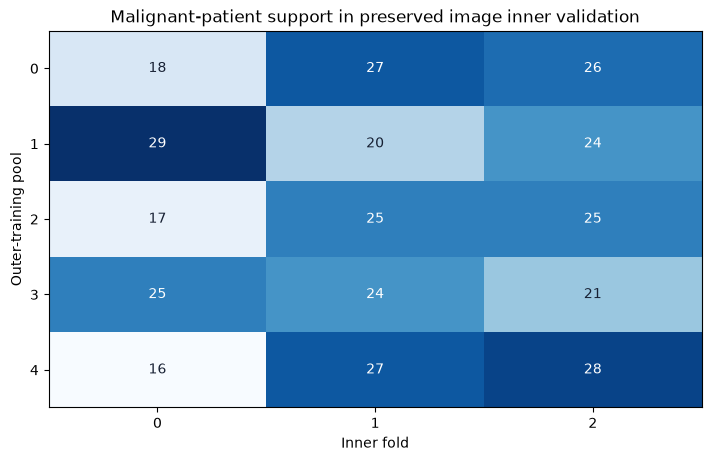

In [9]:
checks = []
for outer in range(5):
    members = load_preserved_inner_memberships(ROOT, dataset_identity, outer)
    assert members.groupby("patient_id").inner_fold.nunique().eq(1).all()
    assert set(members.image_name) == set(data.loc[data.fold.ne(outer), "image_name"])
    for inner, held in members.groupby("inner_fold"):
        fitting = members.loc[members.inner_fold.ne(inner)]
        assert set(fitting.patient_id).isdisjoint(set(held.patient_id))
        checks.append({"outer_fold": outer, "inner_fold": int(inner),
            "held_images": len(held), "held_patients": held.patient_id.nunique(),
            "held_malignant_images": int(held.target.sum()),
            "held_malignant_patients": held.loc[held.target.eq(1), "patient_id"].nunique(),
            "patient_overlap": 0})
display(pd.DataFrame(checks))
support = pd.DataFrame(checks).pivot(index="outer_fold", columns="inner_fold",
    values="held_malignant_patients")
figure, axis = plt.subplots(figsize=(7, 4.5), layout="constrained")
support_image = axis.imshow(support, cmap="Blues", aspect="auto")
for row in range(5):
    for column in range(3):
        value = support.iloc[row, column]
        text_colour = "white" if support_image.norm(value) >= 0.5 else "#172033"
        axis.text(column, row, str(value), ha="center", va="center", color=text_colour)
axis.set(title="Malignant-patient support in preserved image inner validation",
    xlabel="Inner fold", ylabel="Outer-training pool", xticks=range(3), yticks=range(5))
finish_figure(figure, "inner_malignant_patient_support")

## Explain metadata tuning and stopping membership provenance

The historical metadata tuning partition uses seed 42 + outer fold, whereas image selection uses the saved three-way memberships described above. Because a historical metadata membership receipt was not saved, the clean runner reconstructed those memberships from the original row order and then filtered retained IDs. This provenance is recorded explicitly rather than claiming a previously saved manifest existed.

The metadata NN stopping fit uses a designated original outer group within the training pool. These internal groups can differ across modelling procedures while all comparators still share the same outer-held-out records. The receipt, inner audit and saved epochs below document those boundaries; this report neither reconstructs the split again nor starts fitting.

In [10]:
membership_receipt = read_json(ROOT / METADATA_SUITE / "memberships_receipt.json")
display(pd.DataFrame([membership_receipt]))
show_saved_table(METADATA_SUITE + "/inner_audit.csv", 15)
show_saved_table("results/dedup_v1/metadata/epochs.csv", 15)
display(Markdown("**Verified contract:** one retained development population, unchanged outer patient groups, training-only inner and stopping memberships, and zero fitting/validation patient overlap. No splitter or reserved-test reader was called."))

,compatibility_sha256,status,historical_membership_receipt_available,reconstruction_source,versions,original_row_order_used,split_on_retained_rows,seed_rule,output_sha256
0,764a0bf22b45a8bd654119eaa9a15200e53c60096b1d44...,reconstructed_and_frozen,False,data/subset/processed/train_folds.csv,"{'python': '3.14.6', 'numpy': '2.5.2', 'pandas...",True,False,42 + outer_fold,{'results/dedup_v1/metadata_suite/metadata_ful...


,outer_fold,inner_fold,fit_images,validation_images,fit_patients,validation_patients,fit_positive_images,validation_positive_images,patient_overlap,outer_patient_overlap
0,0,0,3528,1834,225,113,70,33,0,0
1,0,1,3658,1704,227,111,68,35,0,0
2,0,2,3538,1824,224,114,68,35,0,0
3,1,0,3528,1812,225,113,66,35,0,0
4,1,1,3634,1706,225,113,69,32,0,0
5,1,2,3518,1822,226,112,67,34,0,0
6,2,0,3564,1814,226,109,67,34,0,0
7,2,1,3602,1776,224,111,68,33,0,0
8,2,2,3590,1788,220,115,67,34,0,0
9,3,0,3532,1803,226,114,68,34,0,0


,base_seed,outer_fold,training_seed,stop_fold,selected_epochs,stop_log_loss,attempted_stopping_epochs,outer_train_patients,score_patients,epoch_fit_patients,epoch_stop_patients,encoded_input_width
0,42,0,42,1,20,0.090664,32,338,84,254,84,10
1,142,0,142,2,18,0.092312,30,338,84,251,87,10
2,242,0,242,3,40,0.087399,52,338,84,256,82,10
3,42,1,43,2,59,0.091075,71,338,84,251,87,10
4,142,1,143,3,26,0.087991,38,338,84,256,82,10
5,242,1,243,4,12,0.095656,24,338,84,253,85,10
6,42,2,44,3,59,0.085894,71,335,87,253,82,10
7,142,2,144,4,12,0.097338,24,335,87,250,85,10
8,242,2,244,0,29,0.083573,41,335,87,251,84,10
9,42,3,45,4,11,0.097379,23,340,82,255,85,10


**Verified contract:** one retained development population, unchanged outer patient groups, training-only inner and stopping memberships, and zero fitting/validation patient overlap. No splitter or reserved-test reader was called.

### Check separation from the reserved test

The original notebook read only reserved-test patient identifiers and required zero overlap. That identifier-only check protects separation between people without using outcomes to choose folds or a model.

**Scope adaptation and deferred check:** this clean documentation run has a development-only access boundary, so even the reserved-test identifier reader is deferred. The table below records that status rather than claiming a newly verified overlap count. Before final scoring, the authorised test-preparation stage should verify patient/image-ID separation and exact-image copies across development and test, then apply the predeclared test-cleaning policy without selecting changes from outcomes.

In [11]:
# The original test-ID reader is intentionally deferred.
display(pd.DataFrame([{"check": "Reserved-test patient and exact-image separation",
    "current_status": "Deferred to authorised final-test preparation",
    "reserved_test_identifiers_loaded": False, "reserved_test_labels_loaded": False}]))
print("No current train–test overlap result is inferred from this notebook.")

,check,current_status,reserved_test_identifiers_loaded,reserved_test_labels_loaded
0,Reserved-test patient and exact-image separation,Deferred to authorised final-test preparation,False,False


No current train–test overlap result is inferred from this notebook.


## Verify one shared fold file

The original workflow saved training rows and assignments in `data/subset/processed/train_folds.csv`. The clean workflow uses the separately frozen `data/subset/processed/dedup_v1/train_folds.csv`, with all retained rows and their unchanged assignments. The checks below confirm that the saved table preserves the retained image order, targets and fold values.

Using this same frozen file in later notebooks makes comparisons easier to interpret: a score difference then cannot be explained by each model receiving a different outer split. **Scope adaptation:** executing this report verifies an existing file; it does not save replacement assignments or regenerate folds.

In [12]:
expected_columns = [*train.columns, "fold"]
saved_folds = pd.read_csv(TRAIN_FOLDS_PATH, dtype={"age_approx": "string"})
assert list(saved_folds.columns) == expected_columns
pd.testing.assert_frame_equal(saved_folds.drop(columns="fold"), train, check_dtype=False)
assert np.array_equal(saved_folds["fold"].to_numpy(), train_folds["fold"].to_numpy())
assert saved_folds["image_name"].equals(train["image_name"])
assert np.array_equal(saved_folds["target"].to_numpy(), train["target"].to_numpy())
print(f"Verified existing shared fold file: {TRAIN_FOLDS_PATH}")
print(f"Saved shape: {saved_folds.shape[0]:,} rows x {saved_folds.shape[1]} columns")
print("No folds were assigned or files rewritten during report execution.")

Verified existing shared fold file: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\dedup_v1\train_folds.csv
Saved shape: 6,706 rows x 9 columns
No folds were assigned or files rewritten during report execution.


## Limitations

Keeping each patient in one fold prevents overlap through the supplied patient identifier. It cannot rule out related patients, incorrect identifiers, visually similar images from different identifiers, or differences between this dataset and future clinical data.

The split balances the image-level target approximately. It does not guarantee equal age, sex, site or patient-level positivity in every fold. Each held-out fold has only 24 to 26 malignant images, so performance measured later can vary considerably between folds.

Reusing these folds to develop models is useful, but repeatedly choosing methods from their scores can make the chosen model's development result optimistic. Freeze the final method before using the reserved test once. This notebook cannot establish model accuracy because it trains no model.

Exact-copy removal retains all patients and makes no claim that patient identifiers are clinically correct. The current notebook verifies only development memberships; reserved-test separation must be verified at final-test preparation, and no test accuracy result is available here.

## Summary

All 6,706 retained images from 422 patients keep one of the original five folds. Each fold has 1,297–1,371 images and 24–26 malignant images, giving malignant shares of 1.79%–2.00%. No development patient spans folds, no row is unassigned, and no retained patient changes their historical outer membership.

The preserved image inner memberships are checked within each outer-training pool; metadata tuning and stopping memberships are documented separately. Reserved-test identifiers and labels remain unopened, so the clean train–test separation check is explicitly deferred.

Keep this shared split for later comparisons. Start with [04_metadata_baselines.ipynb](04_metadata_baselines.ipynb), then continue to the broader [05_metadata_models.ipynb](05_metadata_models.ipynb). Freeze the final procedure before the later single reserved-test evaluation.